# Regression Model

## 1. Loading and Preprocessing the Data

In [162]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [163]:
data = pd.read_csv("imdb_top_1000.csv")

In [164]:
X = data[['No_of_Votes']]
y = data['IMDB_Rating']
print(X) 
print(y) 

     No_of_Votes
0        2343110
1        1620367
2        2303232
3        1129952
4         689845
..           ...
995       166544
996        34075
997        43374
998        26471
999        51853

[1000 rows x 1 columns]
0      9.3
1      9.2
2      9.0
3      9.0
4      9.0
      ... 
995    7.6
996    7.6
997    7.6
998    7.6
999    7.6
Name: IMDB_Rating, Length: 1000, dtype: float64


## 2. Detecting and Removing Outliers

In [165]:
X = data[['No_of_Votes']] 
y = data['IMDB_Rating']

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = ~((X < lower_bound) | (X > upper_bound)).any(axis=1)

X = X[outlier_mask]
y = y[outlier_mask]
data = data.loc[X.index]

print("Outliers:", len(outlier_mask) - outlier_mask.sum())

Outliers: 67


## 3. Splitting the Data

In [166]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 1)
print(X_train)
print(X_test)
print(y_train)
print(y_test)

     No_of_Votes
606       179264
675       481918
497       107290
402       240266
898       411599
..           ...
834       181285
118       299198
975       195663
294        33044
75        787806

[746 rows x 1 columns]
     No_of_Votes
438        98431
835        47102
895        49397
314       290074
757       103330
..           ...
321        57428
235       334320
558        41625
640        50622
131       377884

[187 rows x 1 columns]
606    7.8
675    7.8
497    7.9
402    8.0
898    7.6
      ... 
834    7.7
118    8.3
975    7.6
294    8.1
75     8.4
Name: IMDB_Rating, Length: 746, dtype: float64
438    8.0
835    7.7
895    7.6
314    8.1
757    7.7
      ... 
321    8.1
235    8.1
558    7.9
640    7.8
131    8.2
Name: IMDB_Rating, Length: 187, dtype: float64


In [167]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

## 4. Applying Regression Models & 5. Evaluating Models & 7. Printing the Regression Equation

### Linear Regression

In [168]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()
regressor.fit(X_train, y_train)

LinearRegression()

In [169]:
y_pred = regressor.predict(X_test)
print(y_pred)
print(y_test)

[7.90117824 7.89302121 7.89338592 7.93163348 7.90195677 7.8907487
 7.89513575 7.9028359  7.90300737 7.89275614 7.89746531 7.97007427
 7.90831804 7.94455546 7.9129824  7.89369231 7.88985448 7.96167601
 7.90120112 7.89311243 7.89808445 7.93501697 7.8917939  7.91563471
 7.99038317 7.89181329 7.8896579  7.8963111  7.91782411 7.8967184
 7.92489415 7.95543631 7.89247899 7.90040415 7.89482746 7.89148322
 7.93110397 7.90982965 7.98905034 7.89061442 7.89711506 7.90321571
 7.98155504 7.90020487 7.93182148 7.95663009 7.89268749 7.89014498
 7.92173075 7.9094384  7.91932968 7.91581445 7.89367881 7.89563666
 7.95314807 7.92437989 7.89997222 7.94007147 7.91584893 7.89083643
 7.91393923 7.89377432 7.88983795 7.97338149 7.90359663 7.89729003
 7.98717941 7.88955842 7.89602585 7.8987511  7.99556433 7.89432258
 7.89624054 8.00069256 7.91281236 7.92880746 7.99149718 7.88985639
 7.90222788 7.89717672 7.89343853 7.92681497 7.91200951 7.89222901
 7.92583318 8.0014819  7.90536442 7.94344002 7.89869119 7.900329

In [170]:
from sklearn.metrics import r2_score
print(r2_score(y_test, y_pred))

0.0599691176371695


In [171]:
from sklearn.metrics import mean_squared_error

mse_linear = mean_squared_error(y_test, y_pred)
print(mse_linear)

0.0574072335646178


In [172]:
print(regressor.coef_)
print(regressor.intercept_)

[0.03245822]
7.918900804289544


### Polynomial Regression

In [173]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
poly_reg = PolynomialFeatures(degree = 2)
X_train_poly = poly_reg.fit_transform(X_train)
X_test_poly = poly_reg.transform(X_test)
regressor = LinearRegression()
regressor.fit(X_train_poly, y_train)

LinearRegression()

In [174]:
from sklearn.metrics import r2_score
r2_score(y_test, regressor.predict(poly_reg.transform(X_test)))

0.09827713347218725

In [175]:
y_pred_poly = regressor.predict(X_test_poly)
print(y_pred)
print(y_test)

[7.90117824 7.89302121 7.89338592 7.93163348 7.90195677 7.8907487
 7.89513575 7.9028359  7.90300737 7.89275614 7.89746531 7.97007427
 7.90831804 7.94455546 7.9129824  7.89369231 7.88985448 7.96167601
 7.90120112 7.89311243 7.89808445 7.93501697 7.8917939  7.91563471
 7.99038317 7.89181329 7.8896579  7.8963111  7.91782411 7.8967184
 7.92489415 7.95543631 7.89247899 7.90040415 7.89482746 7.89148322
 7.93110397 7.90982965 7.98905034 7.89061442 7.89711506 7.90321571
 7.98155504 7.90020487 7.93182148 7.95663009 7.89268749 7.89014498
 7.92173075 7.9094384  7.91932968 7.91581445 7.89367881 7.89563666
 7.95314807 7.92437989 7.89997222 7.94007147 7.91584893 7.89083643
 7.91393923 7.89377432 7.88983795 7.97338149 7.90359663 7.89729003
 7.98717941 7.88955842 7.89602585 7.8987511  7.99556433 7.89432258
 7.89624054 8.00069256 7.91281236 7.92880746 7.99149718 7.88985639
 7.90222788 7.89717672 7.89343853 7.92681497 7.91200951 7.89222901
 7.92583318 8.0014819  7.90536442 7.94344002 7.89869119 7.900329

In [176]:
from sklearn.metrics import mean_squared_error
mse_poly = mean_squared_error(y_test, y_pred)
print(mse_poly)

0.0574072335646178


In [177]:
print(regressor.coef_)
print(regressor.intercept_)

[ 0.         -0.00571923  0.03068615]
7.888214655054095


### Ridge Regression

In [178]:
from sklearn.linear_model import Ridge
rdge=Ridge(alpha=0.001)
rdge.fit(X_train,y_train)
y_pred_test=rdge.predict(X_test)
print(r2_score(y_test,y_pred_test))

0.05996905077819903


In [179]:
y_pred_ridge = rdge.predict(X_test)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
print(mse_ridge)

0.057407237647662944


In [180]:
y_pred = rdge.predict(X_test)
print(y_pred)
print(y_test)

[7.90117826 7.89302124 7.89338596 7.93163346 7.90195679 7.89074874
 7.89513579 7.90283592 7.90300739 7.89275617 7.89746534 7.97007421
 7.90831805 7.94455542 7.91298241 7.89369235 7.88985452 7.96167595
 7.90120114 7.89311246 7.89808448 7.93501695 7.89179393 7.91563472
 7.99038307 7.89181332 7.88965794 7.89631113 7.91782411 7.89671843
 7.92489414 7.95543626 7.89247902 7.90040418 7.89482749 7.89148325
 7.93110395 7.90982966 7.98905024 7.89061446 7.89711509 7.90321573
 7.98155496 7.9002049  7.93182146 7.95663004 7.89268752 7.89014502
 7.92173075 7.90943841 7.91932968 7.91581445 7.89367884 7.89563669
 7.95314803 7.92437988 7.89997224 7.94007144 7.91584894 7.89083646
 7.91393924 7.89377435 7.88983799 7.97338141 7.90359665 7.89729006
 7.98717932 7.88955846 7.89602588 7.89875113 7.99556422 7.89432261
 7.89624057 8.00069245 7.91281237 7.92880745 7.99149708 7.88985643
 7.9022279  7.89717675 7.89343856 7.92681496 7.91200952 7.89222905
 7.92583317 8.00148179 7.90536443 7.94343999 7.89869122 7.9003

In [181]:
print(rdge.coef_)
print(rdge.intercept_)

[0.03245818]
7.918900804289544


### Lasso Regression

In [182]:
from sklearn.linear_model import Lasso
las=Lasso(alpha=0.001)
las.fit(X_train,y_train)
y_pred_test=las.predict(X_test)
print(r2_score(y_test,y_pred_test))

0.05841733846182939


In [183]:
y_pred_lasso = las.predict(X_test)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
print(mse_lasso)

0.05750199997201022


In [184]:
y_pred = las.predict(X_test)
print(y_pred)
print(y_test)

[7.90172425 7.89381853 7.89417201 7.9312412  7.90247879 7.89161604
 7.89586793 7.90333084 7.90349702 7.89356162 7.89812571 7.96849768
 7.90864408 7.94376507 7.91316474 7.89446896 7.89074936 7.96035816
 7.90174643 7.89390694 7.89872578 7.93452045 7.89262903 7.91573534
 7.98818088 7.89264782 7.89055884 7.89700706 7.91785728 7.89740182
 7.9247095  7.9543107  7.89329301 7.90097401 7.89556913 7.89232792
 7.930728   7.91010912 7.98688911 7.89148589 7.89778625 7.90369895
 7.97962474 7.90078087 7.9314234  7.9554677  7.89349509 7.89103091
 7.92164357 7.90972993 7.91931647 7.91590954 7.89445587 7.8963534
 7.95209296 7.92421109 7.90055539 7.93941922 7.91594296 7.89170106
 7.91409209 7.89454843 7.89073335 7.971703   7.90406813 7.89795583
 7.98507583 7.89046242 7.8967306  7.89937189 7.99320241 7.8950798
 7.89693868 7.99817265 7.91299994 7.92850225 7.98926057 7.89075121
 7.90274155 7.89784601 7.89422299 7.92657114 7.91222182 7.89305074
 7.9256196  7.99893767 7.90578146 7.942684   7.89931383 7.900901

In [185]:
print(las.coef_)
print(las.intercept_)

[0.03145822]
7.918900804289544


### Elastic Net Regression

In [186]:
from sklearn.linear_model import ElasticNet
enet=ElasticNet(alpha=0.0001)
enet.fit(X_train,y_train)
y_pred_test=enet.predict(X_test)
print(r2_score(y_test,y_pred_test))

0.059889755076704465


In [187]:
y_pred_enet = enet.predict(X_test)
mse_enet = mean_squared_error(y_test, y_pred_enet)
print(mse_enet)

0.05741208019798951


In [188]:
y_pred = enet.predict(X_test)
print(y_pred)
print(y_test)

[7.90120642 7.89306237 7.8934265  7.93161323 7.90198372 7.89079348
 7.89517355 7.90286144 7.90303264 7.89279772 7.8974994  7.96999289
 7.90833487 7.94451466 7.91299181 7.89373241 7.88990067 7.96160798
 7.90122927 7.89315344 7.89811756 7.93499134 7.89183701 7.91563991
 7.99026949 7.89185636 7.88970441 7.89634703 7.91782582 7.89675368
 7.92488461 7.95537821 7.89252101 7.90043357 7.89486574 7.89152682
 7.93108456 7.90984408 7.98893877 7.8906594  7.89714971 7.90324065
 7.9814554  7.90023461 7.93180093 7.95657009 7.89272917 7.89019071
 7.92172625 7.90945345 7.919329   7.91581936 7.89371892 7.89567366
 7.95309361 7.92437118 7.90000232 7.9400378  7.91585379 7.89088106
 7.91394712 7.89381428 7.88988417 7.97329484 7.90362097 7.8973244
 7.98707083 7.88960508 7.89606222 7.89878315 7.9954424  7.89436167
 7.89627658 8.00056248 7.91282204 7.92879171 7.99138172 7.88990258
 7.9022544  7.89721127 7.89347902 7.92680238 7.91202047 7.89227143
 7.92582216 8.00135057 7.90538594 7.943401   7.89872333 7.90035

In [189]:
print(enet.coef_)
print(enet.intercept_)

[0.0324066]
7.918900804289544


## 6. Selecting the Best Model

In [190]:
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial Regression', 'Ridge Regression', 'Lasso Regression', 'Elastic Net Regression'],
    'MSE': [mse_linear, mse_poly, mse_ridge, mse_lasso, mse_enet],
    'R² Score': [
        r2_score(y_test, y_pred),  
        r2_score(y_test, y_pred_poly),  
        r2_score(y_test, y_pred_ridge),  
        r2_score(y_test, y_pred_lasso), 
        r2_score(y_test, y_pred_enet)  
    ]
})

print("Model Comparison Table:")
print(model_comparison.to_string(index=False))

Model Comparison Table:
                 Model      MSE  R² Score
     Linear Regression 0.057407  0.059890
 Polynomial Regression 0.057407  0.098277
      Ridge Regression 0.057407  0.059969
      Lasso Regression 0.057502  0.058417
Elastic Net Regression 0.057412  0.059890


In [191]:
best_model_row = model_comparison.loc[model_comparison['R² Score'].idxmax()]
print("\nBest-Fit Model:")
print(f"Model: {best_model_row['Model']}")
print(f"R2 Score: {best_model_row['R² Score']}")
print(f"MSE: {best_model_row['MSE']}")


Best-Fit Model:
Model: Polynomial Regression
R2 Score: 0.09827713347218725
MSE: 0.0574072335646178


## 8. Visualization

### Linear Regression Visualization

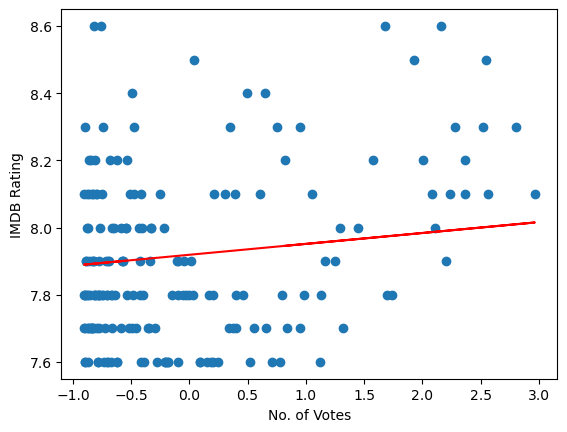

In [192]:
plt.scatter(X_test, y_test)
plt.plot(X_test, y_pred, color='red')
plt.xlabel('No. of Votes')
plt.ylabel('IMDB Rating')
plt.show()

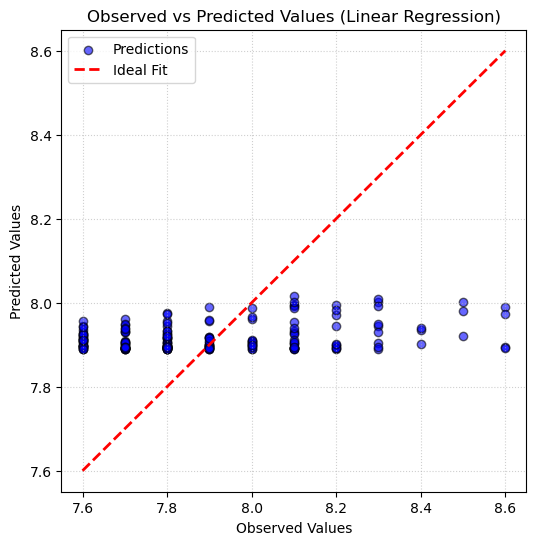

In [193]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.6, edgecolors='k', label='Predictions')

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit')

plt.xlabel('Observed Values')
plt.ylabel('Predicted Values')
plt.title('Observed vs Predicted Values (Linear Regression)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Polynomial Regression Visualization

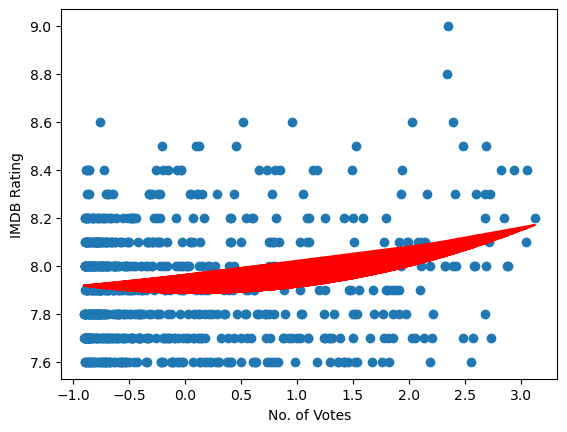

In [194]:
plt.scatter(X_train, y_train)
plt.plot(X_train, regressor.predict(poly_reg.transform(X_train)), color='red')
plt.xlabel('No. of Votes')
plt.ylabel('IMDB Rating')
plt.show()

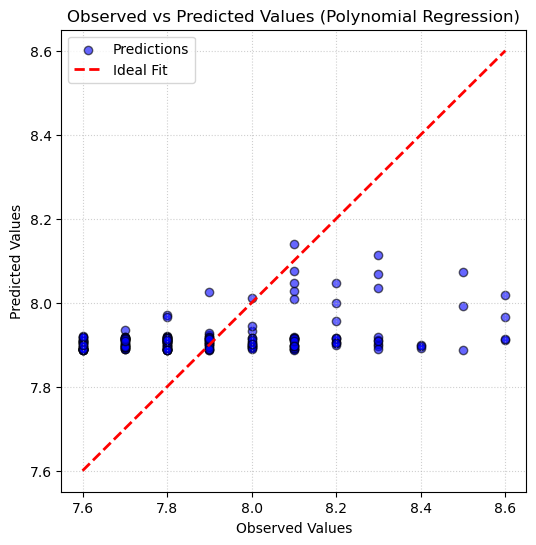

In [195]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_poly, color='blue', alpha=0.6, edgecolors='k', label='Predictions')

min_val = min(y_test.min(), y_pred_poly.min())
max_val = max(y_test.max(), y_pred_poly.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit')

plt.xlabel('Observed Values')
plt.ylabel('Predicted Values')
plt.title('Observed vs Predicted Values (Polynomial Regression)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Ridge Regression Visualization

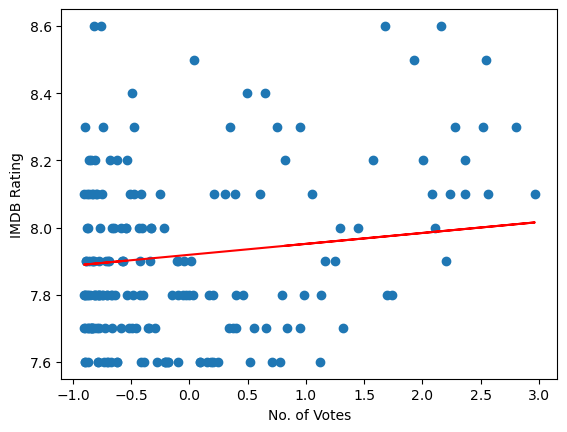

In [196]:
plt.scatter(X_test, y_test)
plt.plot(X_test, rdge.predict(X_test), color='red')
plt.xlabel('No. of Votes')
plt.ylabel('IMDB Rating')
plt.show()

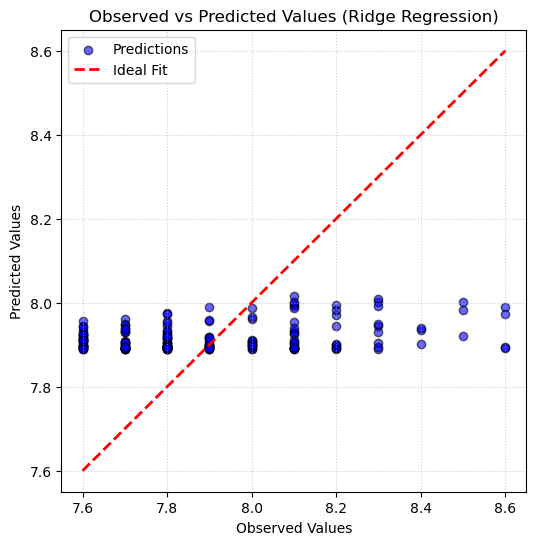

In [197]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_ridge, color='blue', alpha=0.6, edgecolors='k', label='Predictions')

min_val = min(y_test.min(), y_pred_ridge.min())
max_val = max(y_test.max(), y_pred_ridge.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit')

plt.xlabel('Observed Values')
plt.ylabel('Predicted Values')
plt.title('Observed vs Predicted Values (Ridge Regression)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Lasso Regression Visualization

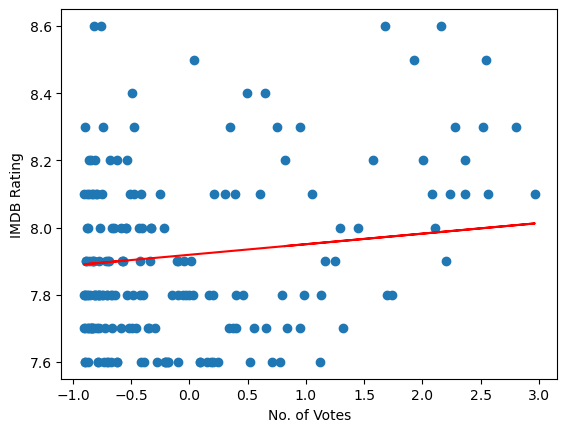

In [198]:
plt.scatter(X_test, y_test)
plt.plot(X_test, las.predict(X_test), color='red')
plt.xlabel('No. of Votes')
plt.ylabel('IMDB Rating')
plt.show()

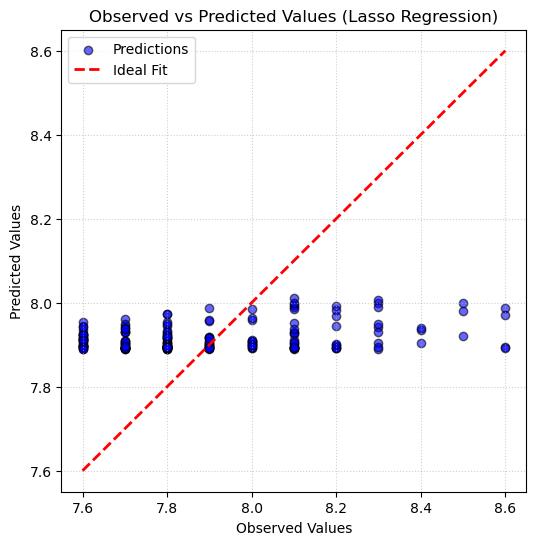

In [199]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_lasso, color='blue', alpha=0.6, edgecolors='k', label='Predictions')

min_val = min(y_test.min(), y_pred_lasso.min())
max_val = max(y_test.max(), y_pred_lasso.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit')

plt.xlabel('Observed Values')
plt.ylabel('Predicted Values')
plt.title('Observed vs Predicted Values (Lasso Regression)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Elastic Net Regression Visualization

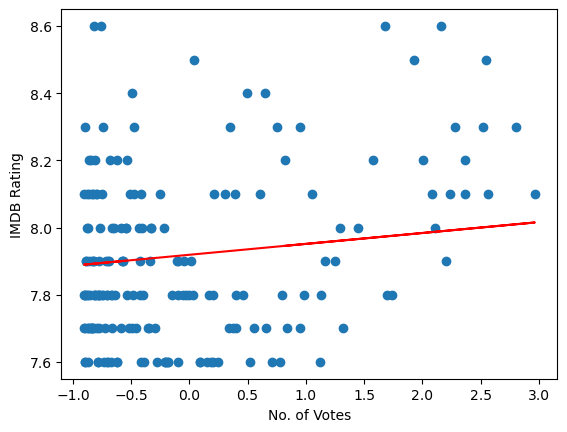

In [200]:
plt.scatter(X_test, y_test)
plt.plot(X_test, enet.predict(X_test), color='red')
plt.xlabel('No. of Votes')
plt.ylabel('IMDB Rating')
plt.show()

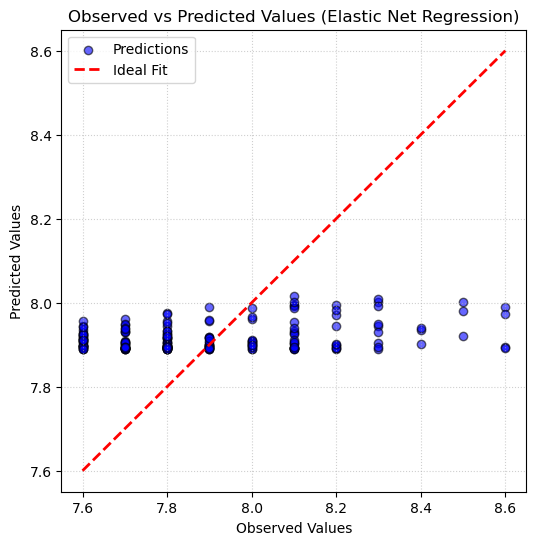

In [201]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_enet, color='blue', alpha=0.6, edgecolors='k', label='Predictions')

min_val = min(y_test.min(), y_pred_enet.min())
max_val = max(y_test.max(), y_pred_enet.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit')

plt.xlabel('Observed Values')
plt.ylabel('Predicted Values')
plt.title('Observed vs Predicted Values (Elastic Net Regression)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# Classification Model

In [202]:
threshold = np.median(y_train)
y_train_class = (y_train > threshold).astype(int)
y_test_class = (y_test > threshold).astype(int)

print({threshold})

{np.float64(7.9)}


In [203]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

classifiers = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes': GaussianNB(),
    'Support Vector Machine': SVC(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

eval_results = []

for name, clf in classifiers.items():
    y_pred_cv = cross_val_predict(clf, X_train, y_train_class, cv=5)
    
    cm = confusion_matrix(y_train_class, y_pred_cv)
    acc = accuracy_score(y_train_class, y_pred_cv)
    prec = precision_score(y_train_class, y_pred_cv, zero_division=0)
    rec = recall_score(y_train_class, y_pred_cv, zero_division=0)
    f1 = f1_score(y_train_class, y_pred_cv, zero_division=0)
    
    errors = int(cm[0, 1] + cm[1, 0])
    
    cm_str = f"[[{cm[0,0]} {cm[0,1]}]\n [ {cm[1,0]} {cm[1,1]}]]"
    
    eval_results.append({
        'Model': name,
        'Confusion Matrix': cm_str,
        'Errors (FP + FN)': errors,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

model_comparison_class = pd.DataFrame(eval_results)

print("Cross-Validation Classification Model Results:")
print(model_comparison_class.to_string(index=False))

best_clf_row = model_comparison_class.loc[model_comparison_class['F1-Score'].idxmax()]
print("\nBest-Fit Model:")
print(f"Model: {best_clf_row['Model']}")
print(f"Accuracy:  {best_clf_row['Accuracy']}")
print(f"Precision: {best_clf_row['Precision']}")
print(f"Recall:    {best_clf_row['Recall']}")
print(f"F1-Score:  {best_clf_row['F1-Score']}")

Cross-Validation Classification Model Results:
                 Model         Confusion Matrix  Errors (FP + FN)  Accuracy  Precision   Recall  F1-Score
   Logistic Regression   [[364 49]\n [ 278 55]]               327  0.561662   0.528846 0.165165  0.251716
   K-Nearest Neighbors [[262 151]\n [ 199 134]]               350  0.530831   0.470175 0.402402  0.433657
           Naive Bayes   [[351 62]\n [ 265 68]]               327  0.561662   0.523077 0.204204  0.293737
Support Vector Machine   [[401 12]\n [ 299 34]]               311  0.583110   0.739130 0.102102  0.179420
         Decision Tree [[241 172]\n [ 167 166]]               339  0.545576   0.491124 0.498498  0.494784
         Random Forest [[241 172]\n [ 167 166]]               339  0.545576   0.491124 0.498498  0.494784

Best-Fit Model:
Model: Decision Tree
Accuracy:  0.5455764075067024
Precision: 0.4911242603550296
Recall:    0.4984984984984985
F1-Score:  0.4947839046199702


In [204]:
best_model_name = model_comparison_class.loc[model_comparison_class['F1-Score'].idxmax(), 'Model']

from sklearn.model_selection import cross_val_predict
best_clf = classifiers[best_model_name]
y_pred_best = cross_val_predict(best_clf, X_train, y_train_class, cv=5)

category_counts = pd.Series(y_pred_best).value_counts().sort_index()

print(f"Best-Fit Classifier: {best_model_name}")
print("Number of elements in each category:")
for cat, count in category_counts.items():
    print(f"Category {cat}: {count} elements")

Best-Fit Classifier: Decision Tree
Number of elements in each category:
Category 0: 408 elements
Category 1: 338 elements


# Cluster Analysis

## K-means Clustering

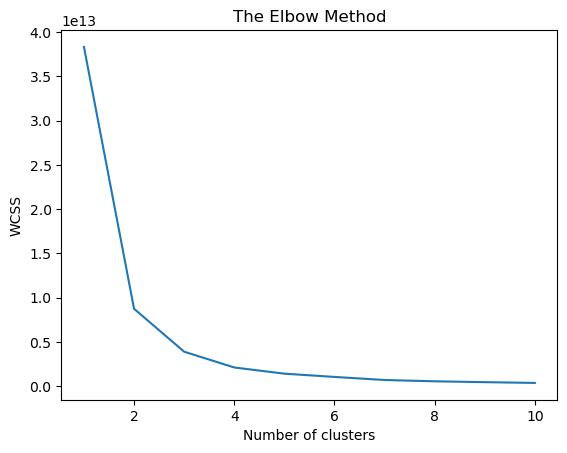

In [205]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
plt.plot(range(1, 11), wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [206]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42)
y_kmeans = kmeans.fit_predict(X)
print(y_kmeans)

[1 1 0 1 0 1 1 1 0 2 2 1 1 1 2 2 2 1 1 2 0 0 0 0 2 0 2 1 1 2 2 0 2 1 2 2 1
 1 0 0 2 0 0 2 2 2 2 0 0 0 2 2 0 0 0 1 1 1 0 1 0 1 2 1 2 1 2 1 1 2 2 0 2 2
 2 0 0 0 2 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 2 2 0 1 1 1 0 0 0 2 2 1 0 1
 1 0 1 1 0 2 1 0 2 1 0 2 0 0 0 0 1 2 2 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 1 2 0 0 0 0 0 1 0 2 1 0 1 2 2 2 0 0 0 1 0 1 1 0 2 0 1 1 0 1 2 0 2 0
 0 0 1 2 1 0 0 0 0 1 0 1 1 0 0 0 2 0 0 0 0 0 2 2 2 0 0 2 0 0 0 1 2 2 2 1 0
 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 2 0 0 0 0 0 0 0 0 0 2 0 0 0
 0 0 0 0 0 0 0 0 0 1 2 1 2 0 0 0 0 0 0 0 1 1 1 2 1 1 0 1 2 0 0 2 0 0 1 1 0
 0 2 2 1 1 0 1 0 0 1 1 1 0 0 0 0 0 0 2 1 0 0 0 1 2 0 0 0 0 0 0 0 0 0 1 0 2
 1 0 2 2 0 2 2 0 1 0 2 0 0 0 1 2 0 0 2 1 2 0 0 2 0 0 0 0 2 2 0 2 0 2 0 2 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 2 2 0 0
 0 0 0 1 1 2 1 0 1 0 2 1 0 2 0 2 2 1 2 0 2 0 1 2 0 0 0 1 2 0 0 1 0 2 1 0 0
 0 0 1 0 1 2 2 1 2 0 0 2 0 0 2 2 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 

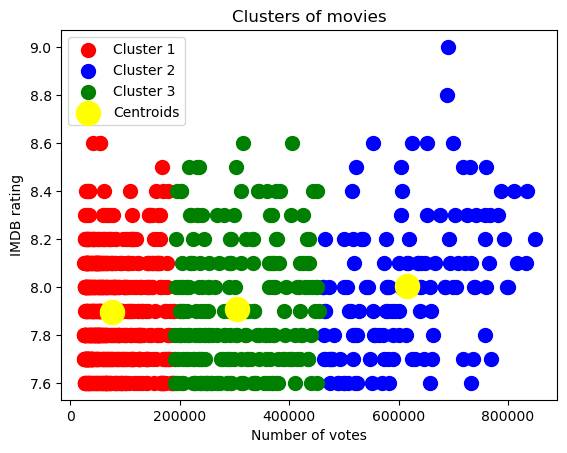

In [207]:
X = data[['No_of_Votes', 'IMDB_Rating']].to_numpy()
y_kmeans = kmeans.fit_predict(X)

plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], s=100, c='red', label='Cluster 1')
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s=100, c='blue', label='Cluster 2')
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s=100, c='green', label='Cluster 3')

plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='yellow', label='Centroids')
plt.title('Clusters of movies')
plt.xlabel('Number of votes')
plt.ylabel('IMDB rating')
plt.legend()
plt.show()

## Heirarchal Clustering

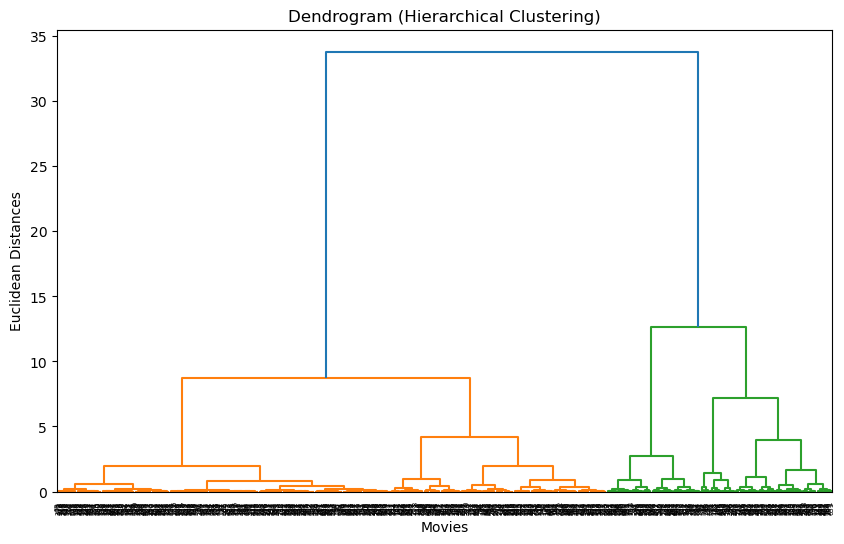

In [208]:
import scipy.cluster.hierarchy as sch
plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(sch.linkage(X_train, method='ward'))
plt.title('Dendrogram (Hierarchical Clustering)')
plt.xlabel('Movies')
plt.ylabel('Euclidean Distances')
plt.show()

In [209]:
from sklearn.cluster import AgglomerativeClustering
X = data[['No_of_Votes', 'IMDB_Rating']].to_numpy()

hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
y_hc = hc.fit_predict(X)

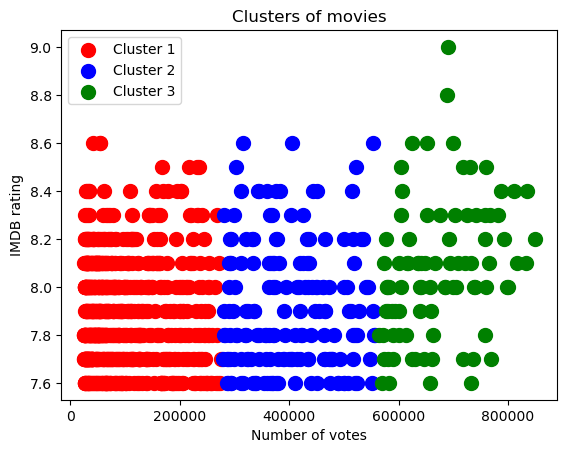

In [210]:
cluster_means = [(i, np.mean(X[y_hc == i, 0])) for i in np.unique(y_hc)]
cluster_means_sorted = sorted(cluster_means, key=lambda x: x[1])
label_mapping = {old_label: new_label for new_label, (old_label, _) in enumerate(cluster_means_sorted)}
y_hc = np.array([label_mapping[label] for label in y_hc])

plt.scatter(X[y_hc == 0, 0], X[y_hc == 0, 1], s = 100, c = 'red', label = 'Cluster 1')
plt.scatter(X[y_hc == 1, 0], X[y_hc == 1, 1], s = 100, c = 'blue', label = 'Cluster 2')
plt.scatter(X[y_hc == 2, 0], X[y_hc == 2, 1], s = 100, c = 'green', label = 'Cluster 3')
plt.title('Clusters of movies')
plt.xlabel('Number of votes')
plt.ylabel('IMDB rating')
plt.legend()
plt.show()